# Crop Yield Prediction Using Machine Learning

### Government of India Agricultural Dataset

**Objective:**  
To develop machine learning models that predict agricultural crop yield
(in tonnes per hectare) using historical district-level agricultural data.

### Machine Learning Models
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Linear Support Vector Regression (LinearSVR)

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

### Dataset Source
India Data Portal (IDP)  
Underlying Source: Ministry of Agriculture & Farmers Welfare, Government of India

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the dataset

file_path = "crop-wise-area-production-yield.csv"

data = pd.read_csv(file_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
# Display the first five rows

data.head()

,id,year,state_name,state_code,district_name,district_code,crop_name,crop_code,crop_type,season,area,area_unit,production,production_unit,yield,yield_unit
0,0,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Arhar/Tur,202.0,Pulses,Kharif,21400.0,Hectare,2600.0,Tonnes,0.121,Tonnes/Hectare
1,1,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Bajra,103.0,Cereals,Kharif,1400.0,Hectare,500.0,Tonnes,0.357,Tonnes/Hectare
2,2,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Castor Seed,1002.0,Oilseeds,Kharif,1000.0,Hectare,100.0,Tonnes,0.100,Tonnes/Hectare
3,3,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Cotton(Lint),1101.0,Fiber Crops,Kharif,7300.0,Hectare,9400.0,Tonnes,1.288,Tonnes/Hectare
4,4,1997-1998,Andhra Pradesh,28,Ananthapuramu,502,Dry Chillies,502.0,Spices,Kharif,3700.0,Hectare,7100.0,Tonnes,1.919,Tonnes/Hectare


In [4]:
rows, columns = data.shape

print("Number of rows:", rows)
print("Number of columns:", columns)

Number of rows: 455359
Number of columns: 16


In [5]:
print("Column names:")
print(data.columns.tolist())

Column names:
['id', 'year', 'state_name', 'state_code', 'district_name', 'district_code', 'crop_name', 'crop_code', 'crop_type', 'season', 'area', 'area_unit', 'production', 'production_unit', 'yield', 'yield_unit']


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 455359 entries, 0 to 455358
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               455359 non-null  int64  
 1   year             455359 non-null  str    
 2   state_name       455359 non-null  str    
 3   state_code       455359 non-null  int64  
 4   district_name    455359 non-null  str    
 5   district_code    455359 non-null  int64  
 6   crop_name        455359 non-null  str    
 7   crop_code        455338 non-null  float64
 8   crop_type        455359 non-null  str    
 9   season           455359 non-null  str    
 10  area             455359 non-null  float64
 11  area_unit        455359 non-null  str    
 12  production       450350 non-null  float64
 13  production_unit  455359 non-null  str    
 14  yield            455359 non-null  float64
 15  yield_unit       455359 non-null  str    
dtypes: float64(4), int64(3), str(9)
memory usage: 55.

In [7]:
data.describe()

,id,state_code,district_code,crop_code,area,production,yield
count,455359.000000,455359.000000,455359.000000,455338.000000,4.553590e+05,4.503500e+05,455359.00000
mean,227679.000000,19.412593,359.423745,468.182563,1.313002e+04,8.380320e+05,68.84521
std,131450.964951,9.430053,185.520710,368.573998,4.846655e+04,2.028612e+07,861.71475
min,0.000000,1.000000,1.000000,101.000000,4.000000e-03,0.000000e+00,0.00000
25%,113839.500000,10.000000,193.000000,107.000000,7.900000e+01,9.100000e+01,0.56300
50%,227679.000000,21.000000,375.000000,288.000000,6.000000e+02,8.080000e+02,1.05100
75%,341518.500000,28.000000,520.000000,708.000000,4.777000e+03,8.350000e+03,2.55000
max,455358.000000,38.000000,765.000000,1503.000000,8.580100e+06,1.597800e+09,43958.33300


In [8]:
data.describe(include="all")

,id,year,state_name,state_code,district_name,district_code,crop_name,crop_code,crop_type,season,area,area_unit,production,production_unit,yield,yield_unit
count,455359.000000,455359,455359,455359.000000,455359,455359.000000,455359,455338.000000,455359,455359,4.553590e+05,455359,4.503500e+05,455359,455359.00000,455359
unique,NaN,26,34,NaN,737,NaN,115,NaN,10,7,NaN,1,NaN,1,NaN,1
top,NaN,2019-2020,Uttar Pradesh,NaN,Belagavi,NaN,Rice,NaN,Cereals,Kharif,NaN,Hectare,NaN,Tonnes,NaN,Tonnes/Hectare
freq,NaN,22186,56511,NaN,1700,NaN,31636,NaN,125657,161402,NaN,455359,NaN,455359,NaN,455359
mean,227679.000000,NaN,NaN,19.412593,NaN,359.423745,NaN,468.182563,NaN,NaN,1.313002e+04,NaN,8.380320e+05,NaN,68.84521,NaN
std,131450.964951,NaN,NaN,9.430053,NaN,185.520710,NaN,368.573998,NaN,NaN,4.846655e+04,NaN,2.028612e+07,NaN,861.71475,NaN
min,0.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,101.000000,NaN,NaN,4.000000e-03,NaN,0.000000e+00,NaN,0.00000,NaN
25%,113839.500000,NaN,NaN,10.000000,NaN,193.000000,NaN,107.000000,NaN,NaN,7.900000e+01,NaN,9.100000e+01,NaN,0.56300,NaN
50%,227679.000000,NaN,NaN,21.000000,NaN,375.000000,NaN,288.000000,NaN,NaN,6.000000e+02,NaN,8.080000e+02,NaN,1.05100,NaN
75%,341518.500000,NaN,NaN,28.000000,NaN,520.000000,NaN,708.000000,NaN,NaN,4.777000e+03,NaN,8.350000e+03,NaN,2.55000,NaN


In [9]:
print(data.dtypes)

id                   int64
year                   str
state_name             str
state_code           int64
district_name          str
district_code        int64
crop_name              str
crop_code          float64
crop_type              str
season                 str
area               float64
area_unit              str
production         float64
production_unit        str
yield              float64
yield_unit             str
dtype: object


In [10]:

missing_values = data.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
id                    0
year                  0
state_name            0
state_code            0
district_name         0
district_code         0
crop_name             0
crop_code            21
crop_type             0
season                0
area                  0
area_unit             0
production         5009
production_unit       0
yield                 0
yield_unit            0
dtype: int64


In [11]:

missing_percentage = (data.isnull().sum() / len(data)) * 100

missing_table = pd.DataFrame({
    "Missing Values": data.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_table

,Missing Values,Missing Percentage
id,0,0.000000
year,0,0.000000
state_name,0,0.000000
state_code,0,0.000000
district_name,0,0.000000
district_code,0,0.000000
crop_name,0,0.000000
crop_code,21,0.004612
crop_type,0,0.000000
season,0,0.000000


In [12]:
duplicate_count = data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [13]:

unique_values = data.nunique()

print("Number of unique values in each column:")
print(unique_values)

Number of unique values in each column:
id                 455359
year                   26
state_name             34
state_code             34
district_name         737
district_code         740
crop_name             115
crop_code              94
crop_type              10
season                  7
area                62881
area_unit               1
production          91878
production_unit         1
yield               33458
yield_unit              1
dtype: int64


In [14]:
print("Year values:")
print(sorted(data["year"].dropna().unique()))

Year values:
['1997-1998', '1998-1999', '1999-2000', '2000-2001', '2001-2002', '2002-2003', '2003-2004', '2004-2005', '2005-2006', '2006-2007', '2007-2008', '2008-2009', '2009-2010', '2010-2011', '2011-2012', '2012-2013', '2013-2014', '2014-2015', '2015-2016', '2016-2017', '2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023']


In [15]:
state_count = data["state_name"].nunique()

print("Number of unique states:", state_count)

print("\nState names:")
print(sorted(data["state_name"].dropna().unique()))

Number of unique states: 34

State names:
['Andaman And Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu And Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'The Dadra And Nagar Haveli And Daman And Diu', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


In [16]:
district_count = data["district_name"].nunique()

print("Number of unique districts:", district_count)

Number of unique districts: 737


In [17]:
crop_count = data["crop_name"].nunique()

print("Number of unique crops:", crop_count)

print("\nFirst 50 crop names:")
print(sorted(data["crop_name"].dropna().unique())[:50])

Number of unique crops: 115

First 50 crop names:
['Apple', 'Arcanut (Processed)', 'Arecanut', 'Arhar/Tur', 'Ash Gourd', 'Atcanut (Raw)', 'Bajra', 'Banana', 'Barley', 'Beet Root', 'Ber', 'Bhindi', 'Bitter Gourd', 'Black Pepper', 'Bottle Gourd', 'Brinjal', 'Cabbage', 'Cardamom', 'Carrot', 'Cashewnut', 'Cashewnut Processed', 'Cashewnut Raw', 'Castor Seed', 'Cauliflower', 'Citrus Fruit', 'Coconut', 'Coffee', 'Colocosia', 'Cond-Spcs Other', 'Coriander', 'Cotton(Lint)', 'Cowpea(Lobia)', 'Cucumber', 'Drum Stick', 'Dry Chillies', 'Dry Ginger', 'Garlic', 'Ginger', 'Gram', 'Grapes', 'Groundnut', 'Guar Seed', 'Horse-Gram', 'Jack Fruit', 'Jobster', 'Jowar', 'Jute', 'Jute & Mesta', 'Kapas', 'Khesari']


In [18]:

print("Number of crop types:", data["crop_type"].nunique())

print("\nCrop types:")
print(sorted(data["crop_type"].dropna().unique()))

Number of crop types: 10

Crop types:
['Cereals', 'Drugs And Narcotics', 'Fiber Crops', 'Fruits', 'Oilseeds', 'Plantation Crops', 'Pulses', 'Spices', 'Sugar', 'Vegetable']


In [19]:
print("Number of seasons:", data["season"].nunique())

print("\nSeasons:")
print(sorted(data["season"].dropna().unique()))

Number of seasons: 7

Seasons:
['Autumn', 'Kharif', 'Rabi', 'Summer', 'Total', 'Whole Year', 'Winter']


In [20]:

print("Target variable: yield")

print("\nMissing values:")
print(data["yield"].isnull().sum())

print("\nMinimum yield:", data["yield"].min())
print("Maximum yield:", data["yield"].max())
print("Mean yield:", data["yield"].mean())
print("Median yield:", data["yield"].median())

Target variable: yield

Missing values:
0

Minimum yield: 0.0
Maximum yield: 43958.333
Mean yield: 68.84521003867279
Median yield: 1.051


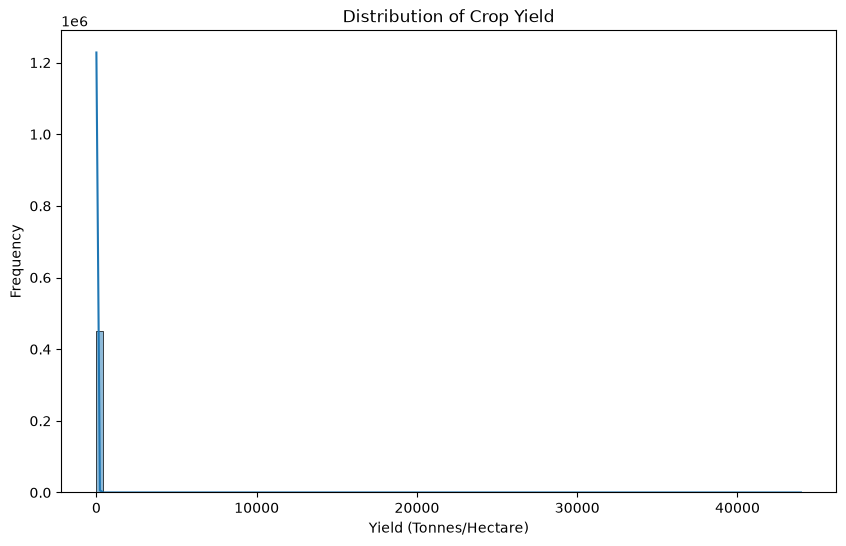

In [21]:

plt.figure(figsize=(10, 6))

sns.histplot(data["yield"], bins=100, kde=True)

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield (Tonnes/Hectare)")
plt.ylabel("Frequency")

plt.show()

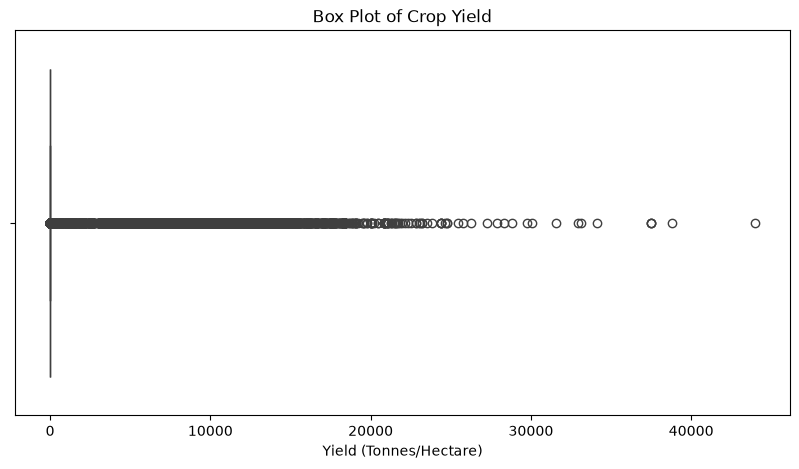

In [22]:

plt.figure(figsize=(10, 5))

sns.boxplot(x=data["yield"])

plt.title("Box Plot of Crop Yield")
plt.xlabel("Yield (Tonnes/Hectare)")

plt.show()

In [23]:
percentiles = data["yield"].quantile([
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.995,
    0.999,
    1.00
])

print("Yield percentiles:")
print(percentiles)

Yield percentiles:
0.500        1.051000
0.750        2.550000
0.900        9.972000
0.950       22.375300
0.990       95.950000
0.995     5941.718270
0.999    14060.049752
1.000    43958.333000
Name: yield, dtype: float64


In [24]:
yield_skewness = data["yield"].skew()

print("Yield skewness:", yield_skewness)

Yield skewness: 16.33191112593695


In [25]:
eda_data = data.copy()

print("EDA dataset shape:", eda_data.shape)


EDA dataset shape: (455359, 16)


In [26]:
# Display unique values for important categorical columns

categorical_columns = [
    "state_name",
    "district_name",
    "crop_name",
    "crop_type",
    "season"
]

for column in categorical_columns:
    print("\n", "=" * 50)
    print("Column:", column)
    print("Number of unique values:", eda_data[column].nunique())
    print("Top 10 values:")
    print(eda_data[column].value_counts().head(10))


Column: state_name
Number of unique values: 34
Top 10 values:
state_name
Uttar Pradesh     56511
Karnataka         39788
Madhya Pradesh    34714
Bihar             29214
Tamil Nadu        29051
Maharashtra       24671
Rajasthan         23355
Assam             22495
Odisha            21635
Chhattisgarh      20135
Name: count, dtype: int64

Column: district_name
Number of unique values: 737
Top 10 values:


district_name
Belagavi          1700
Ballari           1667
Davanagere        1650
Tumakuru          1645
Haveri            1642
Y.S.R. Kadapa     1641
Hassan            1635
Prakasam          1596
Chamarajanagar    1571
Kurnool           1563
Name: count, dtype: int64

Column: crop_name
Number of unique values: 115
Top 10 values:
crop_name
Rice                 31636
Maize                30781
Moong(Green Gram)    23419
Urad                 22104
Groundnut            18623
Sesamum              17307
Onion                14822
Potato               14108
Jowar                13841
Arhar/Tur            13230
Name: count, dtype: int64

Column: crop_type
Number of unique values: 10
Top 10 values:
crop_type
Cereals                125657
Pulses                 112851
Oilseeds                87590
Vegetable               43481
Spices                  42029
Fiber Crops             16452
Sugar                   12483
Fruits                  10192
Drugs And Narcotics      4527
Plantation Crops   

In [27]:
# Average yield by crop type

crop_type_yield = (
    eda_data.groupby("crop_type")["yield"]
    .mean()
    .sort_values(ascending=False)
)

print(crop_type_yield)

crop_type
Oilseeds               335.619194
Sugar                   58.182176
Fruits                  19.270306
Vegetable               11.825369
Fiber Crops              3.523920
Spices                   2.886080
Drugs And Narcotics      2.013177
Cereals                  1.948894
Plantation Crops         1.929474
Pulses                   0.727182
Name: yield, dtype: float64


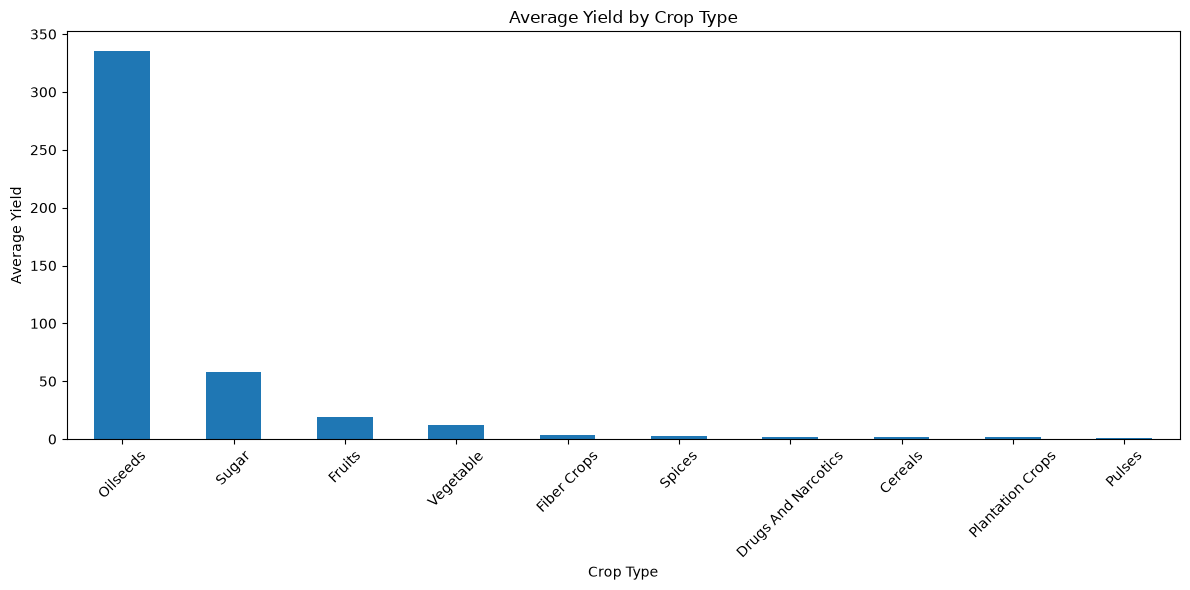

In [28]:
plt.figure(figsize=(12, 6))

crop_type_yield.plot(kind="bar")

plt.title("Average Yield by Crop Type")
plt.xlabel("Crop Type")
plt.ylabel("Average Yield")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [29]:
# Calculate average yield for each crop

crop_yield = (
    eda_data.groupby("crop_name")["yield"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 15 crops by average yield:")
print(crop_yield.head(15))

Top 15 crops by average yield:
crop_name
Coconut         8876.884883
Sugarcane         58.182176
Banana            30.009896
Papaya            29.238914
Tapioca           19.405027
Grapes            19.229891
Pineapple         14.087128
Onion             13.490434
Potato            12.874065
Cabbage           12.545910
Sapota            10.267282
Sweet Potato       9.661702
Jute               9.640089
Colocosia          9.510455
Tomato             8.689002
Name: yield, dtype: float64


In [30]:
print("Bottom 15 crops by average yield:")
print(crop_yield.tail(15))

Bottom 15 crops by average yield:
crop_name
Ber                   0.0
Ash Gourd             0.0
Beet Root             0.0
Lab-Lab               0.0
Litchi                0.0
Other Citrus Fruit    0.0
Other Dry Fruit       0.0
Plums                 0.0
Peach                 0.0
Pear                  0.0
Peas (Vegetable)      0.0
Ribed Guard           0.0
Snak Guard            0.0
Water Melon           0.0
Yam                   0.0
Name: yield, dtype: float64


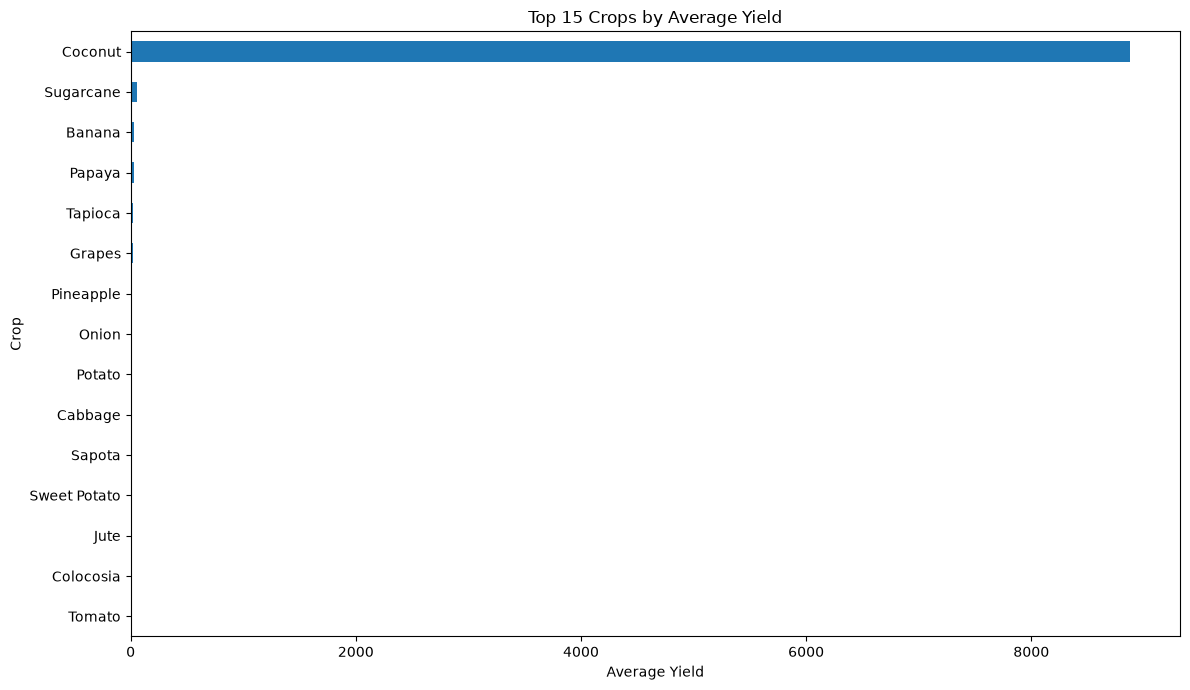

In [31]:
plt.figure(figsize=(12, 7))

crop_yield.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Crops by Average Yield")
plt.xlabel("Average Yield")
plt.ylabel("Crop")
plt.tight_layout()

plt.show()

In [32]:
# Average yield by season

season_yield = (
    eda_data.groupby("season")["yield"]
    .mean()
    .sort_values(ascending=False)
)

print(season_yield)

season
Whole Year    372.988046
Winter          6.063139
Summer          3.503149
Total           2.569275
Kharif          2.524621
Autumn          2.408804
Rabi            2.369403
Name: yield, dtype: float64


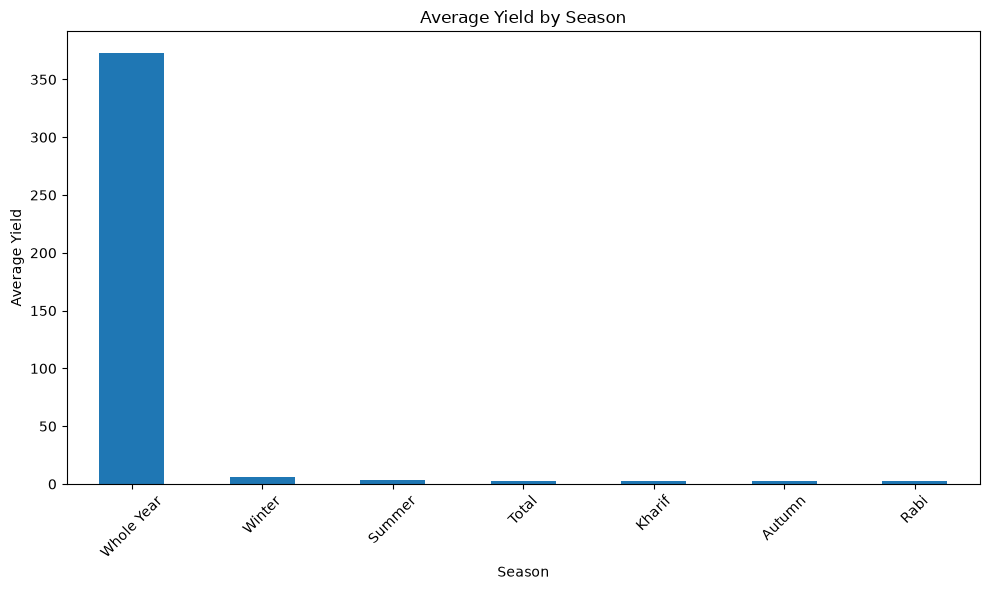

In [33]:
plt.figure(figsize=(10, 6))

season_yield.plot(kind="bar")

plt.title("Average Yield by Season")
plt.xlabel("Season")
plt.ylabel("Average Yield")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [34]:
crop_type_summary = eda_data.groupby("crop_type")["yield"].agg(
    ["count", "mean", "median", "min", "max"]
)

crop_type_summary = crop_type_summary.sort_values(
    by="median",
    ascending=False
)

print(crop_type_summary)

                      count        mean   median  min        max
crop_type                                                       
Sugar                 12483   58.182176  55.9020  0.0   2247.533
Fruits                10192   19.270306  11.3145  0.0   9801.000
Vegetable             43481   11.825369   9.9800  0.0   4070.000
Fiber Crops           16452    3.523920   1.9050  0.0   1022.000
Cereals              125657    1.948894   1.6220  0.0   1494.000
Drugs And Narcotics    4527    2.013177   1.5010  0.0     20.995
Plantation Crops         97    1.929474   1.3350  0.0      8.765
Spices                42029    2.886080   1.2800  0.0    964.800
Oilseeds              87590  335.619194   0.7310  0.0  43958.333
Pulses               112851    0.727182   0.6110  0.0    270.000


In [35]:
# Convert financial/agricultural year into numeric starting year

eda_data["year_start"] = eda_data["year"].str[:4].astype(int)

print(eda_data[["year", "year_start"]].head(10))

        year  year_start
0  1997-1998        1997
1  1997-1998        1997
2  1997-1998        1997
3  1997-1998        1997
4  1997-1998        1997
5  1997-1998        1997
6  1997-1998        1997
7  1997-1998        1997
8  1997-1998        1997
9  1997-1998        1997


In [36]:
print("Minimum year:", eda_data["year_start"].min())
print("Maximum year:", eda_data["year_start"].max())

print("\nUnique years:")
print(sorted(eda_data["year_start"].unique()))

Minimum year: 1997
Maximum year: 2022

Unique years:
[np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]


In [37]:
yearly_yield = (
    eda_data.groupby("year_start")["yield"]
    .mean()
)

print(yearly_yield)

year_start
1997    48.865931
1998    45.127517
1999    46.492933
2000    56.640613
2001    57.991928
2002    60.165643
2003    57.675966
2004    67.013381
2005    78.483336
2006    81.061808
2007    70.317238
2008    84.612936
2009    85.491638
2010    66.384285
2011    86.123507
2012    63.692578
2013    73.810906
2014    81.609274
2015    78.514507
2016    72.336688
2017    71.461332
2018    73.512409
2019    68.860776
2020    50.698432
2021    61.672545
2022    82.906575
Name: yield, dtype: float64


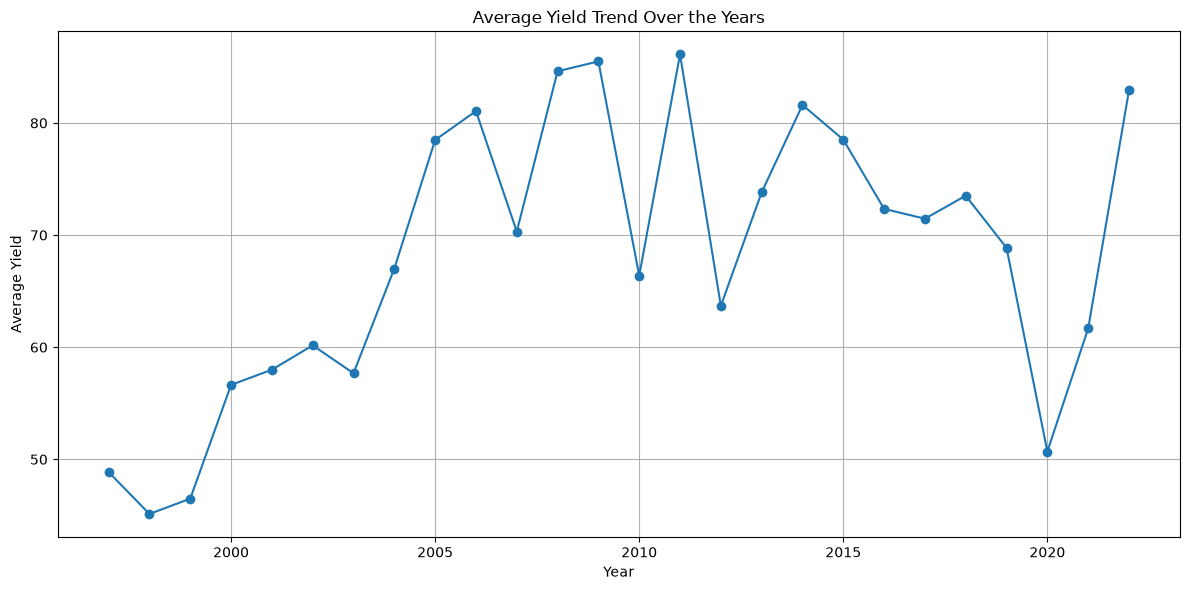

In [38]:
plt.figure(figsize=(12, 6))

yearly_yield.plot(kind="line", marker="o")

plt.title("Average Yield Trend Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Yield")
plt.grid(True)
plt.tight_layout()

plt.show()

In [39]:
state_yield = (
    eda_data.groupby("state_name")["yield"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 15 states by average yield:")
print(state_yield.head(15))

Top 15 states by average yield:
state_name
Puducherry                                      393.891484
Andaman And Nicobar Islands                     365.954476
Kerala                                          349.536248
West Bengal                                     337.992582
Goa                                             284.971829
Tamil Nadu                                      240.138643
Assam                                           221.241208
Andhra Pradesh                                  204.103970
Karnataka                                       125.193547
Telangana                                        43.519997
The Dadra And Nagar Haveli And Daman And Diu     11.433059
Chandigarh                                        7.838677
Punjab                                            7.282341
Haryana                                           6.558088
Uttar Pradesh                                     5.539719
Name: yield, dtype: float64


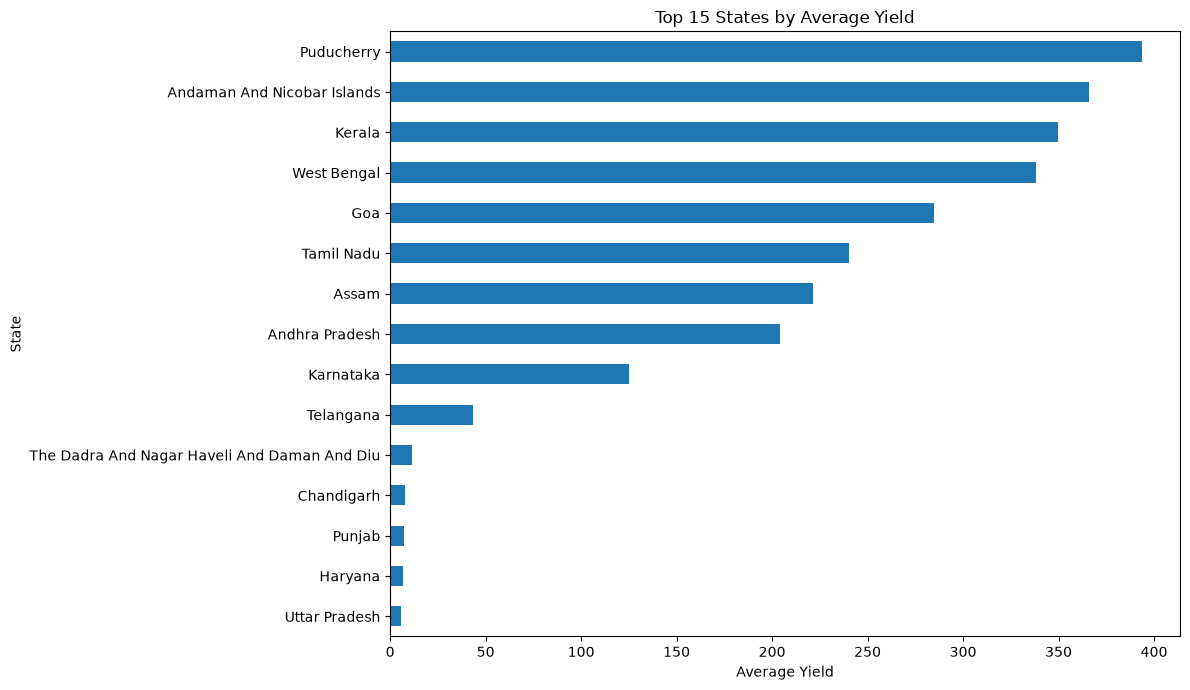

In [40]:
plt.figure(figsize=(12, 7))

state_yield.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 States by Average Yield")
plt.xlabel("Average Yield")
plt.ylabel("State")
plt.tight_layout()

plt.show()

In [41]:
print("Area statistics:")
print(eda_data["area"].describe())

Area statistics:
count    4.553590e+05
mean     1.313002e+04
std      4.846655e+04
min      4.000000e-03
25%      7.900000e+01
50%      6.000000e+02
75%      4.777000e+03
max      8.580100e+06
Name: area, dtype: float64


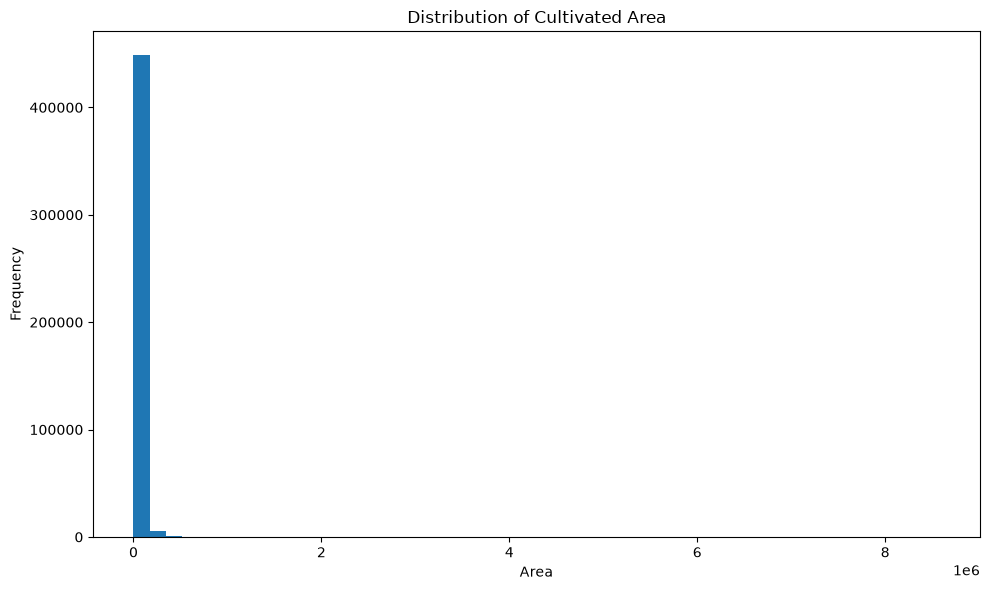

In [42]:
plt.figure(figsize=(10, 6))

plt.hist(eda_data["area"], bins=50)

plt.title("Distribution of Cultivated Area")
plt.xlabel("Area")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

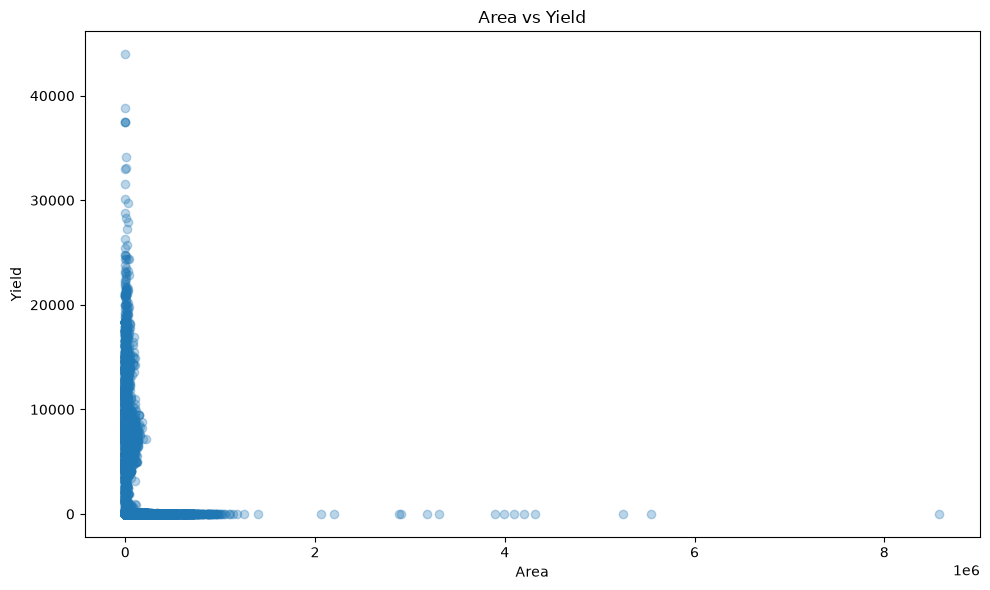

In [43]:
plt.figure(figsize=(10, 6))

plt.scatter(
    eda_data["area"],
    eda_data["yield"],
    alpha=0.3
)

plt.title("Area vs Yield")
plt.xlabel("Area")
plt.ylabel("Yield")

plt.tight_layout()
plt.show()

In [44]:
area_yield_correlation = eda_data["area"].corr(eda_data["yield"])

print("Correlation between Area and Yield:", area_yield_correlation)

Correlation between Area and Yield: -0.0017987970078926444


In [45]:
# Display observations with extremely high yield

high_yield_data = eda_data[
    eda_data["yield"] > eda_data["yield"].quantile(0.99)
]

print("Number of observations above 99th percentile:",
      len(high_yield_data))

print("\nSample of high-yield observations:")
print(
    high_yield_data[
        [
            "year",
            "state_name",
            "district_name",
            "crop_name",
            "crop_type",
            "season",
            "area",
            "yield"
        ]
    ].head(20)
)

Number of observations above 99th percentile: 4552

Sample of high-yield observations:
          year      state_name  district_name  crop_name crop_type  \
31   1997-1998  Andhra Pradesh  Ananthapuramu  Sugarcane     Sugar   
157  1997-1998  Andhra Pradesh        Krishna  Sugarcane     Sugar   
191  1997-1998  Andhra Pradesh        Kurnool  Sugarcane     Sugar   
430  1997-1998  Andhra Pradesh  Y.S.R. Kadapa  Sugarcane     Sugar   
574  1997-1998           Assam        Barpeta    Coconut  Oilseeds   
600  1997-1998           Assam     Bongaigaon    Coconut  Oilseeds   
626  1997-1998           Assam         Cachar    Coconut  Oilseeds   
653  1997-1998           Assam        Darrang    Coconut  Oilseeds   
679  1997-1998           Assam        Dhemaji    Coconut  Oilseeds   
706  1997-1998           Assam         Dhubri    Coconut  Oilseeds   
732  1997-1998           Assam      Dibrugarh    Coconut  Oilseeds   
758  1997-1998           Assam     Dima Hasao    Coconut  Oilseeds   
783

In [46]:
thresholds = [100, 500, 1000, 5000, 10000]

for threshold in thresholds:
    count = (eda_data["yield"] > threshold).sum()
    
    print(
        "Yield greater than",
        threshold,
        ":",
        count
    )

Yield greater than 100 : 4277
Yield greater than 500 : 3255
Yield greater than 1000 : 3222
Yield greater than 5000 : 2543
Yield greater than 10000 : 1182


In [47]:
Q1 = eda_data["yield"].quantile(0.25)
Q3 = eda_data["yield"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outlier_count = (
    (eda_data["yield"] < lower_bound) |
    (eda_data["yield"] > upper_bound)
).sum()

print("Number of IQR outliers:", outlier_count)

Q1: 0.563
Q3: 2.55
IQR: 1.9869999999999999
Lower Bound: -2.4174999999999995
Upper Bound: 5.5305
Number of IQR outliers: 66267


In [48]:
outlier_percentage = (
    outlier_count / len(eda_data)
) * 100

print(
    "Percentage of IQR outliers:",
    outlier_percentage,
    "%"
)

Percentage of IQR outliers: 14.552693589014382 %


In [49]:
# Create a copy of the original dataset for machine learning

ml_data = data.copy()

print("Original shape:", ml_data.shape)

Original shape: (455359, 16)


In [50]:
# Remove columns that are not required for prediction

columns_to_drop = [
    "id",
    "state_code",
    "district_code",
    "crop_code",
    "area_unit",
    "production",
    "production_unit",
    "yield_unit",
    "year"
]

ml_data = ml_data.drop(columns=columns_to_drop)

print("Shape after removing unnecessary columns:", ml_data.shape)
print("\nRemaining columns:")
print(ml_data.columns.tolist())

Shape after removing unnecessary columns: (455359, 7)

Remaining columns:
['state_name', 'district_name', 'crop_name', 'crop_type', 'season', 'area', 'yield']


In [51]:
# Reload the year column from the original data
# and convert it into the starting year

ml_data["year_start"] = data["year"].str[:4].astype(int)

print(ml_data[["year_start"]].head())
print("\nYear range:")
print(ml_data["year_start"].min(), "to", ml_data["year_start"].max())

   year_start
0        1997
1        1997
2        1997
3        1997
4        1997

Year range:
1997 to 2022


In [52]:
# Check missing values after preprocessing

print("Missing values in ML dataset:")
print(ml_data.isnull().sum())

Missing values in ML dataset:
state_name       0
district_name    0
crop_name        0
crop_type        0
season           0
area             0
yield            0
year_start       0
dtype: int64


In [53]:
# Check for duplicate rows

duplicate_count = ml_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [54]:
# Define the target variable

target = "yield"

# Separate features and target

X = ml_data.drop(columns=[target])
y = ml_data[target]

print("Feature columns:")
print(X.columns.tolist())

print("\nTarget column:")
print(target)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Feature columns:
['state_name', 'district_name', 'crop_name', 'crop_type', 'season', 'area', 'year_start']

Target column:
yield

Feature shape: (455359, 7)
Target shape: (455359,)


In [55]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (364287, 7)
Testing data shape: (91072, 7)

Training target shape: (364287,)
Testing target shape: (91072,)


In [56]:
# Define categorical and numerical features

categorical_features = [
    "state_name",
    "district_name",
    "crop_name",
    "crop_type",
    "season"
]

numerical_features = [
    "area",
    "year_start"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['state_name', 'district_name', 'crop_name', 'crop_type', 'season']

Numerical features:
['area', 'year_start']


In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for categorical variables

categorical_preprocessor = OneHotEncoder(
    handle_unknown="ignore"
)

# Preprocessing for numerical variables

numerical_preprocessor = StandardScaler()

# Combine both preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_preprocessor,
            categorical_features
        ),
        (
            "numerical",
            numerical_preprocessor,
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import LinearSVR

print("All four models imported successfully.")

All four models imported successfully.


In [59]:
from sklearn.pipeline import Pipeline

linear_regression_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression pipeline created.")

Linear Regression pipeline created.


In [60]:
decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                random_state=42
            )
        )
    ]
)

print("Decision Tree pipeline created.")

Decision Tree pipeline created.


In [61]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [62]:
linear_svr_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            LinearSVR(
                random_state=42,
                max_iter=5000
            )
        )
    ]
)

print("LinearSVR pipeline created.")

LinearSVR pipeline created.


In [63]:
# Compact diagnostic for the target variable

print("TARGET DIAGNOSTIC")
print("-" * 40)

print("Number of records:", len(y))
print("Minimum:", y.min())
print("Median:", y.median())
print("Mean:", y.mean())
print("Maximum:", y.max())
print("Skewness:", y.skew())

print("\nExtreme-value counts:")

for value in [100, 500, 1000, 5000, 10000]:
    print(
        f"Yield > {value}:",
        (y > value).sum()
    )

TARGET DIAGNOSTIC
----------------------------------------
Number of records: 455359
Minimum: 0.0
Median: 1.051
Mean: 68.84521003867279
Maximum: 43958.333
Skewness: 16.33191112593695

Extreme-value counts:
Yield > 100: 4277
Yield > 500: 3255
Yield > 1000: 3222
Yield > 5000: 2543
Yield > 10000: 1182


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Preprocessing for Linear Regression and LinearSVR
# Numerical features are scaled
linear_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Preprocessing for Decision Tree and Random Forest
# Trees do not require feature scaling
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Linear model preprocessing created.")
print("Tree model preprocessing created.")

Linear model preprocessing created.
Tree model preprocessing created.


In [65]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

import numpy as np

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [66]:
linear_regression_pipeline = TransformedTargetRegressor(
    regressor=Pipeline(
        steps=[
            ("preprocessing", linear_preprocessor),
            ("model", LinearRegression())
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

print("Linear Regression pipeline created.")

Linear Regression pipeline created.


In [67]:
decision_tree_pipeline = TransformedTargetRegressor(
    regressor=Pipeline(
        steps=[
            ("preprocessing", tree_preprocessor),
            (
                "model",
                DecisionTreeRegressor(
                    random_state=42
                )
            )
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

print("Decision Tree pipeline created.")

Decision Tree pipeline created.


In [68]:
random_forest_pipeline = TransformedTargetRegressor(
    regressor=Pipeline(
        steps=[
            ("preprocessing", tree_preprocessor),
            (
                "model",
                RandomForestRegressor(
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [69]:
linear_svr_pipeline = TransformedTargetRegressor(
    regressor=Pipeline(
        steps=[
            ("preprocessing", linear_preprocessor),
            (
                "model",
                LinearSVR(
                    random_state=42,
                    max_iter=5000
                )
            )
        ]
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

print("LinearSVR pipeline created.")

LinearSVR pipeline created.


In [70]:
print("Training Linear Regression...")

linear_regression_pipeline.fit(
    X_train,
    y_train
)

print("Linear Regression training completed.")

Training Linear Regression...
Linear Regression training completed.


In [71]:
print("Training Decision Tree...")

decision_tree_pipeline.fit(
    X_train,
    y_train
)

print("Decision Tree training completed.")

Training Decision Tree...
Decision Tree training completed.


In [72]:
print("Training Random Forest...")

random_forest_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

Training Random Forest...
Random Forest training completed.


In [73]:
print("Training LinearSVR...")

linear_svr_pipeline.fit(
    X_train,
    y_train
)

print("LinearSVR training completed.")

Training LinearSVR...
LinearSVR training completed.


In [74]:
# Generate predictions for the test dataset

linear_predictions = linear_regression_pipeline.predict(X_test)

decision_tree_predictions = decision_tree_pipeline.predict(X_test)

random_forest_predictions = random_forest_pipeline.predict(X_test)

linear_svr_predictions = linear_svr_pipeline.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [75]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Evaluation metrics imported.")

Evaluation metrics imported.


In [76]:
def evaluate_model(actual, predicted):
    """
    Calculate regression evaluation metrics.
    """

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    return mae, mse, rmse, r2

In [77]:
# Evaluate Linear Regression

lr_mae, lr_mse, lr_rmse, lr_r2 = evaluate_model(
    y_test,
    linear_predictions
)

# Evaluate Decision Tree

dt_mae, dt_mse, dt_rmse, dt_r2 = evaluate_model(
    y_test,
    decision_tree_predictions
)

# Evaluate Random Forest

rf_mae, rf_mse, rf_rmse, rf_r2 = evaluate_model(
    y_test,
    random_forest_predictions
)

# Evaluate LinearSVR

svr_mae, svr_mse, svr_rmse, svr_r2 = evaluate_model(
    y_test,
    linear_svr_predictions
)

print("All four models evaluated successfully.")

All four models evaluated successfully.


In [78]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "LinearSVR"
    ],
    "MAE": [
        lr_mae,
        dt_mae,
        rf_mae,
        svr_mae
    ],
    "MSE": [
        lr_mse,
        dt_mse,
        rf_mse,
        svr_mse
    ],
    "RMSE": [
        lr_rmse,
        dt_rmse,
        rf_rmse,
        svr_rmse
    ],
    "R2": [
        lr_r2,
        dt_r2,
        rf_r2,
        svr_r2
    ]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,27.328507,175586.800538,419.030787,0.755717
1,Decision Tree,14.140912,92118.433536,303.510187,0.871841
2,Random Forest,12.336037,59449.366627,243.822408,0.917292
3,LinearSVR,25.935987,145981.446967,382.075185,0.796905


In [79]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully.")

GridSearchCV imported successfully.


In [80]:
# Parameters for Random Forest tuning

param_grid = {
    "regressor__model__n_estimators": [100, 150],
    "regressor__model__max_depth": [None, 20],
    "regressor__model__min_samples_split": [2, 5],
    "regressor__model__min_samples_leaf": [1, 2]
}

print("Parameter grid created.")

Parameter grid created.


In [81]:
rf_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=2
)

print("GridSearchCV object created.")

GridSearchCV object created.


In [82]:
# Create a smaller tuning dataset for memory-safe GridSearchCV

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=20000,
    random_state=42
)

print("Full training dataset:", X_train.shape)
print("GridSearch tuning dataset:", X_tune.shape)

print("\nStarting memory-safe Random Forest GridSearchCV...")
print("Using 20,000 rows with 3-fold cross-validation.")
print("This may take some time.")

rf_grid_search.fit(
    X_tune,
    y_tune
)

print("\nGridSearchCV completed successfully.")

Full training dataset: (364287, 7)
GridSearch tuning dataset: (20000, 7)

Starting memory-safe Random Forest GridSearchCV...
Using 20,000 rows with 3-fold cross-validation.
This may take some time.
Fitting 3 folds for each of 16 candidates, totalling 48 fits


c:\Users\Shravani Ghadge\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
print("Best parameters:")
print(rf_grid_search.best_params_)

print("\nBest cross-validation RMSE:")
print(-rf_grid_search.best_score_)